# Pertemuan 4: Perbandingan Baseline dan Kandidat Model

Notebook ini membandingkan baseline Pertemuan 3 (TF-IDF unigram + Multinomial Naive Bayes) dengan beberapa kandidat model. Perbandingan dilakukan dalam dua eksperimen:

1. **Eksperimen 1** menguji cara merepresentasikan teks untuk Multinomial Naive Bayes.
2. **Eksperimen 2** membandingkan baseline dengan Multinomial Naive Bayes hasil Eksperimen 1, Logistic Regression, dan Decision Tree.

Seluruh perbandingan memakai data validasi yang diambil dari data training. Data testing tidak dipakai pada notebook ini dan disimpan untuk evaluasi akhir.

# A. Dataset dan Preprocessing

## A.1 Dataset

Dataset dan rumusan masalah sama dengan Pertemuan 3. Analisis dataset dan EDA lengkap terdapat pada notebook Pertemuan 3.

| Aspek | Keterangan |
| --- | --- |
| Sumber | Hugging Face: [`locuoco/the-biggest-spam-ham-phish-email-dataset-300000`](https://huggingface.co/datasets/locuoco/the-biggest-spam-ham-phish-email-dataset-300000) |
| Jumlah data mentah | 365.448 pesan |
| Fitur | `text`: isi pesan |
| Target | `label`: 0 = Ham, 1 = Phish, 2 = Spam |

Sel berikut memuat library dan dataset, lalu mencatat versi library agar hasil dapat diulang.

In [2]:
import sys
import subprocess
import time
import gc

try:
    from datasets import load_dataset
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'datasets'])
    from datasets import load_dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

RANDOM_STATE = 42
DATASET_NAME = 'locuoco/the-biggest-spam-ham-phish-email-dataset-300000'
LABEL_NAMES = {0: 'Ham', 1: 'Phish', 2: 'Spam'}
VALID_LABELS = set(LABEL_NAMES)

raw_df = load_dataset(DATASET_NAME, split='train').to_pandas()

print(f'Jumlah baris mentah : {len(raw_df):,}')
print(f'Kolom               : {raw_df.columns.tolist()}')
print(f'Versi library       : scikit-learn {sklearn.__version__}, pandas {pd.__version__}, numpy {np.__version__}')

df.csv: reconstructing file:   0%|          |  0.00B /  631MB            

df.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/365448 [00:00<?, ? examples/s]

Jumlah baris mentah : 365,448
Kolom               : ['label', 'text']
Versi library       : scikit-learn 1.6.1, pandas 2.2.3, numpy 2.1.3


## A.2 Preprocessing

Preprocessing sama dengan Pertemuan 3:

| Langkah | Alasan |
| --- | --- |
| 1. Menghapus baris yang teks atau labelnya kosong | Tidak ada isi atau target yang dapat dipelajari. |
| 2. Menghapus label di luar 0, 1, dan 2 | Penelitian ini hanya mendefinisikan tiga kelas. |
| 3. Mengubah spasi berlebih menjadi satu spasi, lalu menghapus teks yang menjadi kosong | Spasi berlebih tidak membawa informasi. |
| 4. Menghapus seluruh teks yang muncul dengan lebih dari satu label | Label yang benar tidak dapat ditentukan. |
| 5. Menghapus duplikat dengan teks dan label yang sama, dan menyimpan kemunculan pertama | Teks yang sama tidak boleh muncul di data training dan data evaluasi sekaligus. |

Sel berikut menjalankan langkah tersebut dan memeriksa bahwa jumlah data bersih sama dengan Pertemuan 3, yaitu 278.941 pesan.

In [3]:
data = raw_df[['text', 'label']].dropna(subset=['text', 'label']).copy()
data = data[data['label'].isin(VALID_LABELS)].copy()
data['label'] = data['label'].astype(int)
data['clean_text'] = data['text'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
data = data[data['clean_text'].ne('')].copy()

data['dedup_key'] = data['clean_text'].str.lower()
labels_per_key = data.groupby('dedup_key')['label'].nunique()
conflicting_keys = labels_per_key[labels_per_key.gt(1)].index
data = data.loc[~data['dedup_key'].isin(conflicting_keys)]

df_clean = (
    data.drop_duplicates(subset=['dedup_key'], keep='first')
    [['clean_text', 'label']]
    .rename(columns={'clean_text': 'text'})
    .reset_index(drop=True)
)
del raw_df, data
gc.collect()

EXPECTED_CLEAN_ROWS = 278_941
print(f'Jumlah data bersih: {len(df_clean):,}')
if len(df_clean) == EXPECTED_CLEAN_ROWS:
    print('Jumlah data bersih sama dengan Pertemuan 3.')
else:
    print('Jumlah data bersih berbeda dengan Pertemuan 3. Periksa versi dataset sebelum melanjutkan.')

Jumlah data bersih: 278,941
Jumlah data bersih sama dengan Pertemuan 3.


# B. Strategi Evaluasi

## B.1 Pembagian Data

Data bersih dibagi dengan cara yang sama seperti Pertemuan 3: 80% data training dan 20% data testing, secara *stratified*, dengan `random_state=42`. Data testing langsung dibuang dari notebook ini sehingga tidak dapat memengaruhi perbandingan.

Data training kemudian dibagi lagi menjadi dua bagian:

| Bagian | Asal | Kegunaan |
| --- | --- | --- |
| Data fit | 80% data training | Melatih vectorizer dan model |
| Data validasi | 20% data training | Membandingkan model dan memilih konfigurasi |
| Data testing | 20% data bersih | Evaluasi akhir; tidak dipakai pada notebook ini |

Satu data validasi dipakai karena beberapa kandidat membutuhkan beberapa menit untuk dilatih pada ratusan ribu pesan. Validasi silang (*cross-validation*) untuk model terpilih dilakukan pada Pertemuan 5.

Sel berikut membagi data, menampilkan jumlah pesan per kelas pada setiap bagian, dan memeriksa bahwa tidak ada teks yang muncul di data fit sekaligus data validasi.

In [4]:
from sklearn.model_selection import train_test_split

# Bagian testing (20%) tidak disimpan: data testing tidak dipakai pada notebook ini.
X_train_full, _, y_train_full, _ = train_test_split(
    df_clean['text'], df_clean['label'],
    test_size=0.20, random_state=RANDOM_STATE, stratify=df_clean['label']
)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20, random_state=RANDOM_STATE, stratify=y_train_full
)
del df_clean
gc.collect()

split_table = pd.DataFrame({
    'bagian': ['Data training (total)', 'Data fit', 'Data validasi'],
    'jumlah_pesan': [len(X_train_full), len(X_fit), len(X_val)],
})
for class_id, class_name in LABEL_NAMES.items():
    split_table[class_name] = [int((labels == class_id).sum()) for labels in (y_train_full, y_fit, y_val)]
display(split_table)

shared_texts = set(X_fit.str.lower()) & set(X_val.str.lower())
print(f'Teks yang muncul di data fit dan data validasi sekaligus: {len(shared_texts):,}')

,bagian,jumlah_pesan,Ham,Phish,Spam
0,Data training (total),223152,102192,34270,86690
1,Data fit,178521,81753,27416,69352
2,Data validasi,44631,20439,6854,17338


Teks yang muncul di data fit dan data validasi sekaligus: 0


## B.2 Metrik dan Aturan Pemilihan

Metrik utama adalah **Macro F1**, karena memberi bobot yang sama pada Ham, Phish, dan Spam. **Phish Recall** dilaporkan tersendiri karena Phish yang tidak terdeteksi adalah kesalahan yang paling berisiko. Accuracy, Macro Precision, Macro Recall, Phish Precision, jumlah fitur, dan waktu training dilaporkan sebagai pelengkap.

Aturan pemilihan konfigurasi:

1. Konfigurasi dengan Macro F1 tertinggi pada data validasi dipilih.
2. Jika selisih Macro F1 kurang dari 0,001, dipilih konfigurasi dengan jumlah fitur paling sedikit.

Sel berikut menyiapkan fungsi evaluasi. Setiap model dilatih pada data fit, lalu diuji pada data validasi. Vectorizer berada di dalam *pipeline*, sehingga vocabulary hanya dipelajari dari data fit.

In [5]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.pipeline import Pipeline

TIE_TOLERANCE = 0.001
METRIC_COLUMNS = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1', 'Phish Precision', 'Phish Recall']
results = []      # satu baris per konfigurasi
predictions = {}  # prediksi data validasi per konfigurasi
mnb_mass = {}     # total bobot kata per kelas dan total smoothing (Multinomial Naive Bayes)


def evaluate(name, experiment, pipeline, configuration):
    start = time.perf_counter()
    pipeline.fit(X_fit, y_fit)
    fit_seconds = time.perf_counter() - start
    y_pred = pipeline.predict(X_val)
    predictions[name] = y_pred

    classifier = pipeline.named_steps['classifier']
    if hasattr(classifier, 'feature_count_'):
        n_features = classifier.feature_count_.shape[1]
        mnb_mass[name] = {
            'alpha': classifier.alpha,
            'Jumlah fitur': n_features,
            'Total smoothing (alpha × jumlah fitur)': classifier.alpha * n_features,
            **{f'Total bobot {LABEL_NAMES[c]}': classifier.feature_count_[i].sum()
               for i, c in enumerate(classifier.classes_)},
        }
    details = configuration
    if hasattr(classifier, 'n_iter_'):
        details += f'; iterasi = {int(np.max(classifier.n_iter_))}'
    if hasattr(classifier, 'get_depth'):
        details += f'; kedalaman = {classifier.get_depth()}, daun = {classifier.get_n_leaves():,}'

    row = {
        'eksperimen': experiment,
        'model': name,
        'konfigurasi': details,
        'Jumlah fitur': len(pipeline.named_steps['vectorizer'].vocabulary_),
        'Accuracy': accuracy_score(y_val, y_pred),
        'Macro Precision': precision_score(y_val, y_pred, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_val, y_pred, average='macro', zero_division=0),
        'Macro F1': f1_score(y_val, y_pred, average='macro', zero_division=0),
        'Phish Precision': precision_score(y_val, y_pred, labels=[1], average='macro', zero_division=0),
        'Phish Recall': recall_score(y_val, y_pred, labels=[1], average='macro', zero_division=0),
        'Waktu training (detik)': round(fit_seconds, 1),
    }
    results.append(row)
    return row


def results_frame(names):
    table = pd.DataFrame([row for row in results if row['model'] in names])
    return table.set_index('model').loc[list(names)].reset_index()


def show_table(table):
    columns = ['model', 'konfigurasi', 'Jumlah fitur'] + METRIC_COLUMNS + ['Waktu training (detik)']
    display(table[columns].round(4))


def pick_best(table):
    best_f1 = table['Macro F1'].max()
    close = table[table['Macro F1'] >= best_f1 - TIE_TOLERANCE]
    return close.sort_values('Jumlah fitur', kind='stable').iloc[0]


def change_text(delta):
    if abs(delta) < TIE_TOLERANCE:
        return 'hampir tidak berubah'
    return f'naik {delta:.4f}' if delta > 0 else f'turun {abs(delta):.4f}'

# C. Baseline

Baseline sama dengan Pertemuan 3: TF-IDF unigram dengan seluruh kosakata (`lowercase=True`, `sublinear_tf=True`) dan Multinomial Naive Bayes (`alpha=1.0`). Pada notebook ini, baseline dilatih pada data fit dan diuji pada data validasi, sehingga hasilnya dapat dibandingkan langsung dengan setiap kandidat.

In [6]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

TFIDF_BASE = {'lowercase': True, 'ngram_range': (1, 1), 'sublinear_tf': True}
COUNT_BASE = {'lowercase': True, 'ngram_range': (1, 1)}
WEIGHTING_LABEL = {'tfidf': 'TF-IDF', 'count': 'count'}


def make_vectorizer(weighting, **params):
    if weighting == 'count':
        return CountVectorizer(**{**COUNT_BASE, **params})
    return TfidfVectorizer(**{**TFIDF_BASE, **params})


def mnb_pipeline(vectorizer, alpha=1.0):
    return Pipeline([('vectorizer', vectorizer), ('classifier', MultinomialNB(alpha=alpha))])


BASELINE_NAME = 'MNB + TF-IDF'
evaluate(BASELINE_NAME, 'Baseline', mnb_pipeline(make_vectorizer('tfidf')), 'unigram, seluruh kosakata')
show_table(results_frame([BASELINE_NAME]))

,model,konfigurasi,Jumlah fitur,Accuracy,Macro Precision,Macro Recall,Macro F1,Phish Precision,Phish Recall,Waktu training (detik)
0,MNB + TF-IDF,"unigram, seluruh kosakata",664008,0.8815,0.9073,0.8008,0.8286,0.9827,0.5144,49.3


# D. Eksperimen 1: Representasi Teks untuk Multinomial Naive Bayes

Multinomial Naive Bayes memodelkan berapa kali setiap kata muncul pada pesan. Baseline memberinya bobot TF-IDF yang telah dinormalisasi, bukan jumlah kemunculan kata. Eksperimen ini menguji apakah cara merepresentasikan teks mengubah hasil. Setiap langkah hanya mengubah satu faktor:

| Langkah | Faktor yang diuji | Konfigurasi yang dibandingkan |
| --- | --- | --- |
| D.1 | Pembobotan kata | TF-IDF vs frekuensi kata (*count*) |
| D.2 | Ukuran kosakata | Seluruh kosakata vs 50.000 kata, untuk kedua pembobotan |
| D.3 | Penyebab pengaruh ukuran kosakata | Total bobot kelas vs total *smoothing*; uji α = 0,1 |
| D.4 | Panjang frasa | Unigram vs unigram + bigram |

Langkah D.4 memakai pembobotan terbaik dari D.1.

## D.1 Pembobotan Kata

Sel berikut membandingkan TF-IDF dengan frekuensi kata. Kedua konfigurasi memakai unigram dan seluruh kosakata data fit.

In [7]:
EXP1 = 'Eksperimen 1'
COUNT_NAME = 'MNB + count'
evaluate(COUNT_NAME, EXP1, mnb_pipeline(make_vectorizer('count')), 'unigram, seluruh kosakata')

weighting_table = results_frame([BASELINE_NAME, COUNT_NAME])
show_table(weighting_table)

best_weighting_row = pick_best(weighting_table)
BEST_WEIGHTING = 'count' if best_weighting_row['model'] == COUNT_NAME else 'tfidf'

tfidf_row, count_row = weighting_table.iloc[0], weighting_table.iloc[1]
weighting_text = (
    f"Dibandingkan TF-IDF, frekuensi kata membuat Macro F1 {change_text(count_row['Macro F1'] - tfidf_row['Macro F1'])} "
    f"dan Phish Recall {change_text(count_row['Phish Recall'] - tfidf_row['Phish Recall'])}."
)
display(Markdown(f"{weighting_text} Langkah D.4 memakai pembobotan **{WEIGHTING_LABEL[BEST_WEIGHTING]}**."))

,model,konfigurasi,Jumlah fitur,Accuracy,Macro Precision,Macro Recall,Macro F1,Phish Precision,Phish Recall,Waktu training (detik)
0,MNB + TF-IDF,"unigram, seluruh kosakata",664008,0.8815,0.9073,0.8008,0.8286,0.9827,0.5144,49.3
1,MNB + count,"unigram, seluruh kosakata",664008,0.9397,0.9277,0.9392,0.9323,0.8763,0.9498,48.3


Dibandingkan TF-IDF, frekuensi kata membuat Macro F1 naik 0.1038 dan Phish Recall naik 0.4354. Langkah D.4 memakai pembobotan **count**.

## D.2 Ukuran Kosakata

Membatasi kosakata mengurangi memori dan waktu training, tetapi membuang kata yang jarang muncul. Batas 50.000 kata menyimpan 50.000 kata dengan jumlah kemunculan terbanyak pada seluruh data fit dan membuang sisanya.

Sel berikut membandingkan seluruh kosakata dengan 50.000 kata untuk kedua pembobotan.

In [8]:
VOCAB_CAP = 50_000
TFIDF_CAP_NAME = 'MNB + TF-IDF (50.000 kata)'
COUNT_CAP_NAME = 'MNB + count (50.000 kata)'
evaluate(TFIDF_CAP_NAME, EXP1, mnb_pipeline(make_vectorizer('tfidf', max_features=VOCAB_CAP)), 'unigram, 50.000 kata')
gc.collect()
evaluate(COUNT_CAP_NAME, EXP1, mnb_pipeline(make_vectorizer('count', max_features=VOCAB_CAP)), 'unigram, 50.000 kata')
gc.collect()

show_table(results_frame([BASELINE_NAME, TFIDF_CAP_NAME, COUNT_NAME, COUNT_CAP_NAME]))

def cap_delta(full_name, cap_name, metric):
    pair = results_frame([full_name, cap_name])
    return pair.iloc[1][metric] - pair.iloc[0][metric]

tfidf_cap_f1 = cap_delta(BASELINE_NAME, TFIDF_CAP_NAME, 'Macro F1')
count_cap_f1 = cap_delta(COUNT_NAME, COUNT_CAP_NAME, 'Macro F1')
vocab_text = (
    f"Batas 50.000 kata membuat Macro F1 TF-IDF {change_text(tfidf_cap_f1)} "
    f"(Phish Recall {change_text(cap_delta(BASELINE_NAME, TFIDF_CAP_NAME, 'Phish Recall'))}), "
    f"sedangkan Macro F1 count {change_text(count_cap_f1)} "
    f"(Phish Recall {change_text(cap_delta(COUNT_NAME, COUNT_CAP_NAME, 'Phish Recall'))})."
)
display(Markdown(f"{vocab_text} Langkah D.3 memeriksa penyebab pengaruh ukuran kosakata."))

,model,konfigurasi,Jumlah fitur,Accuracy,Macro Precision,Macro Recall,Macro F1,Phish Precision,Phish Recall,Waktu training (detik)
0,MNB + TF-IDF,"unigram, seluruh kosakata",664008,0.8815,0.9073,0.8008,0.8286,0.9827,0.5144,49.3
1,MNB + TF-IDF (50.000 kata),"unigram, 50.000 kata",50000,0.9200,0.9211,0.8792,0.8961,0.9315,0.7359,47.8
2,MNB + count,"unigram, seluruh kosakata",664008,0.9397,0.9277,0.9392,0.9323,0.8763,0.9498,48.3
3,MNB + count (50.000 kata),"unigram, 50.000 kata",50000,0.9374,0.9240,0.9454,0.9324,0.8601,0.9876,51.1


Batas 50.000 kata membuat Macro F1 TF-IDF naik 0.0675 (Phish Recall naik 0.2215), sedangkan Macro F1 count hampir tidak berubah (Phish Recall naik 0.0378). Langkah D.3 memeriksa penyebab pengaruh ukuran kosakata.

## D.3 Mengapa Ukuran Kosakata Berpengaruh?

Multinomial Naive Bayes menghitung probabilitas kata $w$ pada kelas $c$ sebagai:

$$P(w \mid c) = \frac{\text{bobot } w \text{ pada kelas } c + \alpha}{\text{total bobot kelas } c + \alpha \cdot |V|}$$

dengan $|V|$ adalah jumlah fitur. *Laplace smoothing* menambahkan $\alpha$ pada setiap kata, sehingga total tambahan pada setiap kelas adalah $\alpha \cdot |V|$.

Jika total bobot suatu kelas jauh lebih kecil daripada $\alpha \cdot |V|$, probabilitas kata pada kelas tersebut didominasi oleh smoothing dan menjadi hampir sama untuk semua kata. Akibatnya, kata-kata khas kelas tersebut kehilangan pengaruhnya. TF-IDF menormalisasi setiap pesan sehingga total bobotnya hanya beberapa satuan, sedangkan count menjumlahkan seluruh kemunculan kata. Karena itu, total bobot kelas pada TF-IDF jauh lebih kecil daripada pada count.

Sel berikut menampilkan total bobot setiap kelas dan total smoothing untuk keempat konfigurasi D.1 dan D.2. Rasio di bawah 1 berarti smoothing lebih besar daripada seluruh bobot kata kelas tersebut.

In [9]:
mass_names = [BASELINE_NAME, TFIDF_CAP_NAME, COUNT_NAME, COUNT_CAP_NAME]
mass_table = pd.DataFrame([{'model': name, **mnb_mass[name]} for name in mass_names])
for class_name in LABEL_NAMES.values():
    mass_table[f'Rasio {class_name}'] = (
        mass_table[f'Total bobot {class_name}'] / mass_table['Total smoothing (alpha × jumlah fitur)']
    )
display(mass_table.round(2))

,model,alpha,Jumlah fitur,Total smoothing (alpha × jumlah fitur),Total bobot Ham,Total bobot Phish,Total bobot Spam,Rasio Ham,Rasio Phish,Rasio Spam
0,MNB + TF-IDF,1.0,664008,664008.0,732751.32,207177.80,577119.98,1.10,0.31,0.87
1,MNB + TF-IDF (50.000 kata),1.0,50000,50000.0,724380.73,196308.63,550657.56,14.49,3.93,11.01
2,MNB + count,1.0,664008,664008.0,26395957.00,3249018.00,13650634.00,39.75,4.89,20.56
3,MNB + count (50.000 kata),1.0,50000,50000.0,25635478.00,2850118.00,12867199.00,512.71,57.00,257.34


Jika penjelasan di atas benar, menurunkan $\alpha$ pada seluruh kosakata seharusnya memberi efek yang mirip dengan membatasi kosakata, karena keduanya memperkecil total smoothing. Sel berikut melatih TF-IDF dengan seluruh kosakata dan $\alpha = 0{,}1$. Nilai ini dipilih agar total smoothing ($0{,}1 \times |V|$) mendekati total smoothing batas 50.000 kata pada $\alpha = 1$.

Langkah ini adalah uji penjelasan, bukan *tuning*. Nilai $\alpha$ terbaik dicari pada Pertemuan 5.

In [10]:
ALPHA_CHECK = 0.1
ALPHA_NAME = 'MNB + TF-IDF (alpha = 0.1)'
evaluate(ALPHA_NAME, EXP1, mnb_pipeline(make_vectorizer('tfidf'), alpha=ALPHA_CHECK),
         'unigram, seluruh kosakata, alpha=0.1')
gc.collect()

check_table = results_frame([BASELINE_NAME, TFIDF_CAP_NAME, ALPHA_NAME])
show_table(check_table)

base_check, cap_check, alpha_check = check_table.iloc[0], check_table.iloc[1], check_table.iloc[2]
baseline_mass = mnb_mass[BASELINE_NAME]
phish_ratio = baseline_mass['Total bobot Phish'] / baseline_mass['Total smoothing (alpha × jumlah fitur)']
alpha_gain = alpha_check['Macro F1'] - base_check['Macro F1']
cap_gain = cap_check['Macro F1'] - base_check['Macro F1']

smoothing_text = (
    f"Pada TF-IDF dengan seluruh kosakata dan α = 1, total bobot Phish hanya {phish_ratio:.2f} kali total smoothing. "
    f"Menurunkan α menjadi 0,1 tanpa membuang satu kata pun membuat Macro F1 {change_text(alpha_gain)} "
    f"dan Phish Recall {change_text(alpha_check['Phish Recall'] - base_check['Phish Recall'])}. "
    f"Sebagai pembanding, batas 50.000 kata membuat Macro F1 {change_text(cap_gain)}. "
)
if alpha_gain > TIE_TOLERANCE:
    smoothing_text += (
        'Karena α = 0,1 tetap memakai seluruh kata, kenaikan ini berasal dari smoothing yang lebih kecil, '
        'bukan dari kata yang dibuang. Hasil ini mendukung penjelasan bahwa batas kosakata membantu TF-IDF '
        'karena memperkecil total smoothing.'
    )
else:
    smoothing_text += (
        'Menurunkan α tidak memperbaiki hasil, sehingga pengaruh batas kosakata tidak berasal dari smoothing. '
        'Kemungkinan lain adalah batas kosakata membuang kata langka yang tidak informatif.'
    )
display(Markdown(smoothing_text))

,model,konfigurasi,Jumlah fitur,Accuracy,Macro Precision,Macro Recall,Macro F1,Phish Precision,Phish Recall,Waktu training (detik)
0,MNB + TF-IDF,"unigram, seluruh kosakata",664008,0.8815,0.9073,0.8008,0.8286,0.9827,0.5144,49.3
1,MNB + TF-IDF (50.000 kata),"unigram, 50.000 kata",50000,0.9200,0.9211,0.8792,0.8961,0.9315,0.7359,47.8
2,MNB + TF-IDF (alpha = 0.1),"unigram, seluruh kosakata, alpha=0.1",664008,0.9215,0.9247,0.8703,0.8905,0.9413,0.6875,52.2


Pada TF-IDF dengan seluruh kosakata dan α = 1, total bobot Phish hanya 0.31 kali total smoothing. Menurunkan α menjadi 0,1 tanpa membuang satu kata pun membuat Macro F1 naik 0.0619 dan Phish Recall naik 0.1730. Sebagai pembanding, batas 50.000 kata membuat Macro F1 naik 0.0675. Karena α = 0,1 tetap memakai seluruh kata, kenaikan ini berasal dari smoothing yang lebih kecil, bukan dari kata yang dibuang. Hasil ini mendukung penjelasan bahwa batas kosakata membantu TF-IDF karena memperkecil total smoothing.

## D.4 Unigram dan Bigram

Bigram adalah pasangan dua kata berurutan, misalnya *verify account*. Langkah ini menguji hipotesis 2 pada Pertemuan 3 (F.3): unigram tidak menangkap frasa yang membedakan Phish dari Spam.

Langkah ini tidak memakai batas 50.000 kata. Jika jumlah fitur dibatasi, bigram akan menggantikan sebagian unigram, sehingga perbedaan hasil tidak lagi hanya berasal dari penambahan bigram. Jumlah bigram unik sangat besar, sehingga kedua konfigurasi hanya memakai kata dan frasa yang muncul di minimal dua pesan data fit (`min_df=2`). Langkah ini membutuhkan beberapa menit dan memori yang lebih besar.

In [11]:
label = WEIGHTING_LABEL[BEST_WEIGHTING]
UNI_NAME = f'MNB + {label} unigram (min_df=2)'
BI_NAME = f'MNB + {label} unigram + bigram (min_df=2)'
evaluate(UNI_NAME, EXP1, mnb_pipeline(make_vectorizer(BEST_WEIGHTING, ngram_range=(1, 1), min_df=2)),
         'unigram, min_df=2')
gc.collect()
evaluate(BI_NAME, EXP1, mnb_pipeline(make_vectorizer(BEST_WEIGHTING, ngram_range=(1, 2), min_df=2)),
         'unigram + bigram, min_df=2')
gc.collect()

ngram_table = results_frame([UNI_NAME, BI_NAME])
show_table(ngram_table)

uni_row, bi_row = ngram_table.iloc[0], ngram_table.iloc[1]
bigram_helps = bi_row['Macro F1'] > uni_row['Macro F1'] + TIE_TOLERANCE
display(Markdown(
    f"Menambahkan bigram membuat Macro F1 {change_text(bi_row['Macro F1'] - uni_row['Macro F1'])} "
    f"dan Phish Recall {change_text(bi_row['Phish Recall'] - uni_row['Phish Recall'])}. "
    f"Hasil ini **{'mendukung' if bigram_helps else 'tidak mendukung'}** hipotesis 2."
))

,model,konfigurasi,Jumlah fitur,Accuracy,Macro Precision,Macro Recall,Macro F1,Phish Precision,Phish Recall,Waktu training (detik)
0,MNB + count unigram (min_df=2),"unigram, min_df=2",316448,0.9406,0.9260,0.9470,0.9342,0.8576,0.9835,48.6
1,MNB + count unigram + bigram (min_df=2),"unigram + bigram, min_df=2",3343363,0.9524,0.9388,0.9518,0.9443,0.8820,0.9603,145.4


Menambahkan bigram membuat Macro F1 naik 0.0101 dan Phish Recall turun 0.0232. Hasil ini **mendukung** hipotesis 2.

## D.5 Ringkasan Eksperimen 1

Tabel berikut menampilkan seluruh konfigurasi Multinomial Naive Bayes. Konfigurasi terbaik dipilih dengan aturan B.2 dan menjadi Kandidat 1 pada Eksperimen 2.

In [12]:
mnb_names = [BASELINE_NAME, COUNT_NAME, TFIDF_CAP_NAME, COUNT_CAP_NAME, ALPHA_NAME, UNI_NAME, BI_NAME]
mnb_table = results_frame(mnb_names)
show_table(mnb_table)

BEST_MNB = pick_best(mnb_table)
baseline_row = mnb_table.iloc[0]
if BEST_MNB['model'] == BASELINE_NAME:
    exp1_text = 'Konfigurasi terbaik adalah konfigurasi baseline. Perubahan representasi tidak memperbaiki Multinomial Naive Bayes.'
else:
    exp1_text = (
        f"Konfigurasi terbaik adalah **{BEST_MNB['model']}** ({BEST_MNB['konfigurasi']}). "
        f"Dibandingkan baseline, Macro F1 {change_text(BEST_MNB['Macro F1'] - baseline_row['Macro F1'])} "
        f"dan Phish Recall {change_text(BEST_MNB['Phish Recall'] - baseline_row['Phish Recall'])}."
    )
display(Markdown(exp1_text))

,model,konfigurasi,Jumlah fitur,Accuracy,Macro Precision,Macro Recall,Macro F1,Phish Precision,Phish Recall,Waktu training (detik)
0,MNB + TF-IDF,"unigram, seluruh kosakata",664008,0.8815,0.9073,0.8008,0.8286,0.9827,0.5144,49.3
1,MNB + count,"unigram, seluruh kosakata",664008,0.9397,0.9277,0.9392,0.9323,0.8763,0.9498,48.3
2,MNB + TF-IDF (50.000 kata),"unigram, 50.000 kata",50000,0.9200,0.9211,0.8792,0.8961,0.9315,0.7359,47.8
3,MNB + count (50.000 kata),"unigram, 50.000 kata",50000,0.9374,0.9240,0.9454,0.9324,0.8601,0.9876,51.1
4,MNB + TF-IDF (alpha = 0.1),"unigram, seluruh kosakata, alpha=0.1",664008,0.9215,0.9247,0.8703,0.8905,0.9413,0.6875,52.2
5,MNB + count unigram (min_df=2),"unigram, min_df=2",316448,0.9406,0.9260,0.9470,0.9342,0.8576,0.9835,48.6
6,MNB + count unigram + bigram (min_df=2),"unigram + bigram, min_df=2",3343363,0.9524,0.9388,0.9518,0.9443,0.8820,0.9603,145.4


Konfigurasi terbaik adalah **MNB + count unigram + bigram (min_df=2)** (unigram + bigram, min_df=2). Dibandingkan baseline, Macro F1 naik 0.1157 dan Phish Recall naik 0.4459.

# E. Eksperimen 2: Kandidat Model

## E.1 Alasan Pemilihan Kandidat

| Kandidat | Model | Representasi | Alasan |
| --- | --- | --- | --- |
| Kandidat 1 | Multinomial Naive Bayes | Konfigurasi terbaik Eksperimen 1 | Algoritma sama dengan baseline, sehingga perbedaannya hanya berasal dari representasi teks. |
| Kandidat 2 | Logistic Regression | TF-IDF unigram, seluruh kosakata | Model linear yang umum dipakai untuk klasifikasi teks. Model ini mempelajari bobot setiap kata untuk setiap kelas langsung dari kesalahan prediksi, sehingga dapat membedakan kata yang dipakai bersama oleh Phish dan Spam. |
| Kandidat 3 | Decision Tree | TF-IDF unigram, kata yang muncul di minimal 5 pesan | Model berupa rangkaian aturan ya/tidak yang mudah dibaca. Model ini menunjukkan apakah aturan sederhana pada beberapa kata sudah cukup untuk memisahkan kelas. |

**K-Nearest Neighbors tidak dipakai.** Untuk memprediksi satu pesan, KNN harus menghitung jarak ke seluruh pesan data fit (lebih dari 178 ribu pesan) pada ratusan ribu dimensi kata. Selain mahal, jarak pada ruang berdimensi sangat tinggi menjadi kurang bermakna (*curse of dimensionality*). Karena itu, KNN tidak sesuai dengan karakteristik data teks ini.

## E.2 Konfigurasi Kandidat

| Model | Parameter | Nilai | Alasan |
| --- | --- | --- | --- |
| Logistic Regression | `C` | `1.0` | Nilai bawaan. Regularisasi L2 mencegah bobot kata menjadi terlalu besar. Nilai lain diuji pada tahap tuning. |
| Logistic Regression | `solver` | `lbfgs` (bawaan) | Menangani tiga kelas sekaligus dengan fungsi *softmax*. |
| Logistic Regression | `max_iter` | `1000` | Memberi cukup iterasi agar model konvergen pada ratusan ribu fitur. Jumlah iterasi yang dipakai dicatat pada tabel hasil. |
| Decision Tree | `max_depth` | `20` | Membatasi ukuran pohon agar tetap dapat dibaca dan waktu training terkendali. Nilai lain diuji pada tahap tuning. |
| Decision Tree | `min_df` | `5` | Setiap percabangan memeriksa seluruh kata, sehingga waktu training bertambah sesuai ukuran kosakata. Kata yang muncul di kurang dari 5 pesan juga terlalu jarang untuk membentuk aturan yang umum. |
| Keduanya | `class_weight` | Tidak dipakai | Penanganan ketidakseimbangan kelas diuji terpisah pada Pertemuan 5, sehingga pengaruhnya dapat diukur sendiri. |

## E.3 Logistic Regression

Sel berikut melatih Logistic Regression. Proses ini membutuhkan beberapa menit.

In [13]:
from sklearn.linear_model import LogisticRegression

EXP2 = 'Eksperimen 2'
LR_NAME = 'Logistic Regression + TF-IDF'
evaluate(
    LR_NAME, EXP2,
    Pipeline([
        ('vectorizer', make_vectorizer('tfidf')),
        ('classifier', LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    'unigram, seluruh kosakata, C=1.0'
)
gc.collect()
show_table(results_frame([LR_NAME]))

,model,konfigurasi,Jumlah fitur,Accuracy,Macro Precision,Macro Recall,Macro F1,Phish Precision,Phish Recall,Waktu training (detik)
0,Logistic Regression + TF-IDF,"unigram, seluruh kosakata, C=1.0; iterasi = 82",664008,0.9696,0.9683,0.9615,0.9647,0.9674,0.932,139.0


## E.4 Decision Tree

Sel berikut melatih Decision Tree. Proses ini membutuhkan beberapa menit.

In [14]:
from sklearn.tree import DecisionTreeClassifier

DT_NAME = 'Decision Tree + TF-IDF'
evaluate(
    DT_NAME, EXP2,
    Pipeline([
        ('vectorizer', make_vectorizer('tfidf', min_df=5)),
        ('classifier', DecisionTreeClassifier(max_depth=20, random_state=RANDOM_STATE)),
    ]),
    'unigram, min_df=5, max_depth=20'
)
gc.collect()
show_table(results_frame([DT_NAME]))

,model,konfigurasi,Jumlah fitur,Accuracy,Macro Precision,Macro Recall,Macro F1,Phish Precision,Phish Recall,Waktu training (detik)
0,Decision Tree + TF-IDF,"unigram, min_df=5, max_depth=20; kedalaman = 2...",123566,0.903,0.9083,0.8983,0.9022,0.9282,0.8764,233.3


# F. Perbandingan Model

## F.1 Tabel Perbandingan

Tabel berikut membandingkan baseline dengan ketiga kandidat pada data validasi yang sama. Kolom *Selisih Macro F1* menunjukkan perubahan dibandingkan baseline.

In [15]:
comparison_spec = [
    ('Baseline', BASELINE_NAME),
    ('Kandidat 1', BEST_MNB['model']),
    ('Kandidat 2', LR_NAME),
    ('Kandidat 3', DT_NAME),
]
comparison = results_frame([name for _, name in comparison_spec])
comparison.insert(0, 'peran', [role for role, _ in comparison_spec])
comparison['Selisih Macro F1'] = comparison['Macro F1'] - comparison.loc[0, 'Macro F1']
display(comparison[['peran', 'model', 'konfigurasi', 'Jumlah fitur'] + METRIC_COLUMNS
                   + ['Selisih Macro F1', 'Waktu training (detik)']].round(4))

,peran,model,konfigurasi,Jumlah fitur,Accuracy,Macro Precision,Macro Recall,Macro F1,Phish Precision,Phish Recall,Selisih Macro F1,Waktu training (detik)
0,Baseline,MNB + TF-IDF,"unigram, seluruh kosakata",664008,0.8815,0.9073,0.8008,0.8286,0.9827,0.5144,0.0000,49.3
1,Kandidat 1,MNB + count unigram + bigram (min_df=2),"unigram + bigram, min_df=2",3343363,0.9524,0.9388,0.9518,0.9443,0.8820,0.9603,0.1157,145.4
2,Kandidat 2,Logistic Regression + TF-IDF,"unigram, seluruh kosakata, C=1.0; iterasi = 82",664008,0.9696,0.9683,0.9615,0.9647,0.9674,0.9320,0.1361,139.0
3,Kandidat 3,Decision Tree + TF-IDF,"unigram, min_df=5, max_depth=20; kedalaman = 2...",123566,0.9030,0.9083,0.8983,0.9022,0.9282,0.8764,0.0736,233.3


## F.2 Grafik Perbandingan

Grafik berikut menampilkan Macro F1 dan Phish Recall setiap model. Baseline ditandai abu-abu.

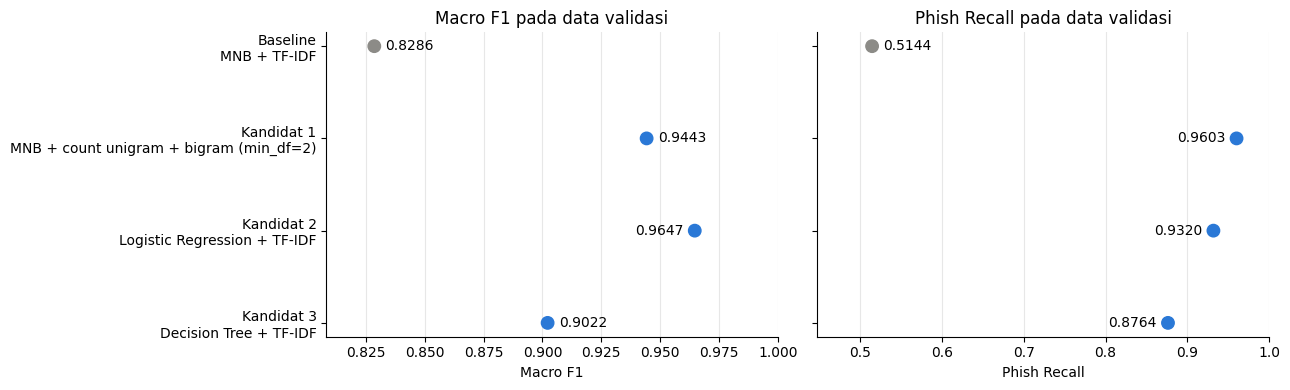

In [16]:
plot_labels = [f'{role}\n{name}' for role, name in comparison_spec]
y_positions = np.arange(len(comparison))[::-1]
dot_colors = ['#8c8b87'] + ['#2a78d6'] * (len(comparison) - 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, metric in zip(axes, ['Macro F1', 'Phish Recall']):
    values = comparison[metric].to_numpy()
    ax.scatter(values, y_positions, s=80, color=dot_colors, zorder=3)
    span = max(values.max() - values.min(), 0.02)
    x_min, x_max = values.min() - 0.15 * span, min(values.max() + 0.35 * span, 1.0)
    ax.set_xlim(x_min, x_max)
    for x_value, y_value in zip(values, y_positions):
        near_edge = x_value > x_max - 0.25 * (x_max - x_min)
        ax.annotate(f'{x_value:.4f}', (x_value, y_value), xytext=(-8, 0) if near_edge else (8, 0),
                    textcoords='offset points', va='center', ha='right' if near_edge else 'left')
    ax.set_title(f'{metric} pada data validasi')
    ax.set_xlabel(metric)
    ax.grid(axis='x', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_yticks(y_positions, plot_labels)
plt.tight_layout()
plt.show()

## F.3 Analisis Kesalahan

Confusion matrix berikut dinormalisasi per baris. Setiap baris menunjukkan ke kelas mana pesan dari satu kelas aktual diprediksi. Setiap sel menampilkan persentase dan jumlah pesan. Tabel di bawahnya membandingkan jumlah setiap jenis kesalahan antar model.

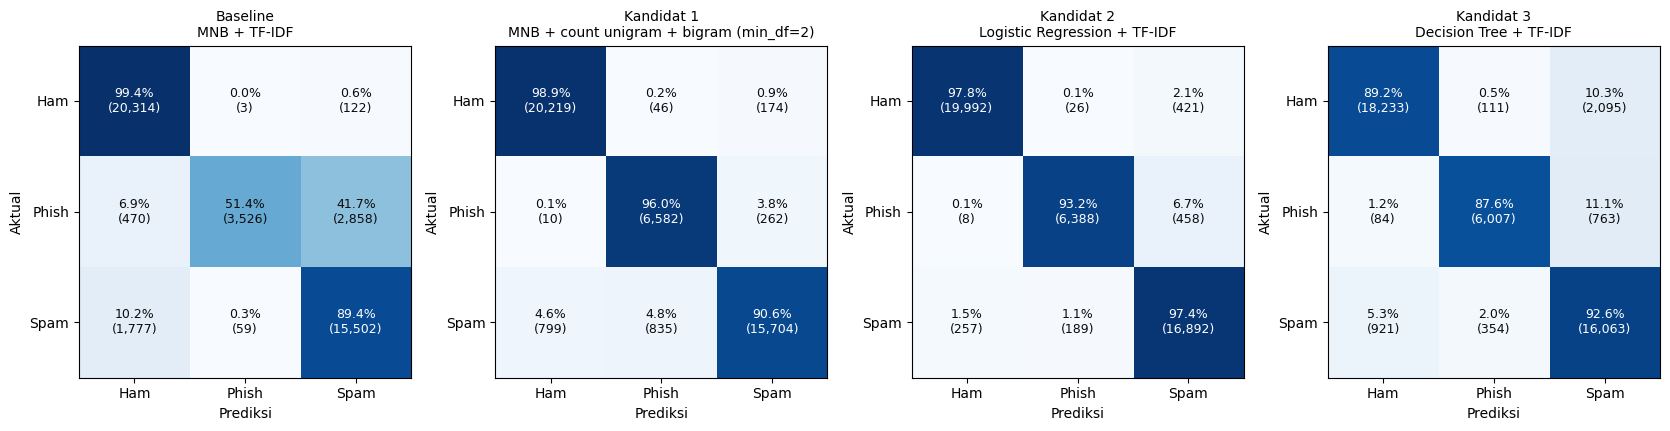

,Baseline,Kandidat 1,Kandidat 2,Kandidat 3
kesalahan (aktual → prediksi),,,,
Phish → Spam,2858,262,458,763
Phish → Ham,470,10,8,84
Spam → Ham,1777,799,257,921
Ham → Spam,122,174,421,2095
Spam → Phish,59,835,189,354
Ham → Phish,3,46,26,111


In [17]:
CLASS_IDS = [0, 1, 2]
CLASS_ORDER = [LABEL_NAMES[c] for c in CLASS_IDS]

fig, axes = plt.subplots(1, len(comparison_spec), figsize=(4.2 * len(comparison_spec), 4.2))
for ax, (role, name) in zip(axes, comparison_spec):
    counts = confusion_matrix(y_val, predictions[name], labels=CLASS_IDS)
    row_share = counts / counts.sum(axis=1, keepdims=True)
    ax.imshow(row_share, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{row_share[i, j] * 100:.1f}%\n({counts[i, j]:,})', ha='center', va='center',
                    fontsize=9, color='white' if row_share[i, j] > 0.6 else '#0b0b0b')
    ax.set_xticks(range(3), CLASS_ORDER)
    ax.set_yticks(range(3), CLASS_ORDER)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
    ax.set_title(f'{role}\n{name}', fontsize=10)
plt.tight_layout()
plt.show()

ERROR_PAIRS = [(1, 2), (1, 0), (2, 0), (0, 2), (2, 1), (0, 1)]
error_table = pd.DataFrame(
    {role: [int(confusion_matrix(y_val, predictions[name], labels=CLASS_IDS)[a, p]) for a, p in ERROR_PAIRS]
     for role, name in comparison_spec},
    index=[f'{LABEL_NAMES[a]} → {LABEL_NAMES[p]}' for a, p in ERROR_PAIRS]
)
error_table.index.name = 'kesalahan (aktual → prediksi)'
display(error_table)

# G. Temuan Awal

## G.1 Temuan dan Model Terpilih

Sel berikut merangkum temuan dari kedua eksperimen. Untuk setiap algoritma, hanya konfigurasi terbaiknya yang diperhitungkan. Dua algoritma dengan Macro F1 tertinggi dibawa ke Pertemuan 5.

In [18]:
best_per_algorithm = pd.DataFrame([
    {**BEST_MNB.to_dict(), 'algoritma': 'Multinomial Naive Bayes'},
    {**results_frame([LR_NAME]).iloc[0].to_dict(), 'algoritma': 'Logistic Regression'},
    {**results_frame([DT_NAME]).iloc[0].to_dict(), 'algoritma': 'Decision Tree'},
]).sort_values('Macro F1', ascending=False).reset_index(drop=True)
shortlist = best_per_algorithm.head(2)
top, runner_up, last = best_per_algorithm.iloc[0], best_per_algorithm.iloc[1], best_per_algorithm.iloc[-1]
baseline_row = results_frame([BASELINE_NAME]).iloc[0]
baseline_errors = error_table.loc['Phish → Spam', 'Baseline']
top_role = comparison.loc[comparison['model'] == top['model'], 'peran'].iloc[0]
top_errors = error_table.loc['Phish → Spam', top_role]

findings_text = f'''
### Temuan

1. **Representasi teks.** {weighting_text} {exp1_text}
2. **Ukuran kosakata dan smoothing.** {vocab_text} Pada seluruh kosakata, total bobot Phish pada TF-IDF hanya {phish_ratio:.2f} kali total smoothing, dan menurunkan α menjadi 0,1 membuat Macro F1 TF-IDF {change_text(alpha_gain)}.
3. **Bigram.** Tanpa batas kosakata, menambahkan bigram membuat Macro F1 {change_text(bi_row['Macro F1'] - uni_row['Macro F1'])}. Hipotesis 2 Pertemuan 3 **{'didukung' if bigram_helps else 'tidak didukung'}**.
4. **Model terbaik.** {top['algoritma']} ({top['model']}) memperoleh Macro F1 tertinggi, yaitu {top['Macro F1']:.4f}, dengan Phish Recall {top['Phish Recall']:.4f} dan Phish Precision {top['Phish Precision']:.4f}. Kesalahan Phish → Spam berubah dari {baseline_errors:,} pada baseline menjadi {top_errors:,} pesan. {runner_up['algoritma']} memperoleh Macro F1 {runner_up['Macro F1']:.4f}, Phish Recall {runner_up['Phish Recall']:.4f}, dan Phish Precision {runner_up['Phish Precision']:.4f}.
5. **Model terlemah.** {last['algoritma']} memperoleh Macro F1 terendah, yaitu {last['Macro F1']:.4f}.

### Model yang dibawa ke Pertemuan 5

{chr(10).join(f"- **{row['algoritma']}**: {row['model']} ({row['konfigurasi']})" for _, row in shortlist.iterrows())}
'''
display(Markdown(findings_text))
display(best_per_algorithm[['algoritma', 'model', 'Macro F1', 'Phish Precision', 'Phish Recall', 'Waktu training (detik)']].round(4))


### Temuan

1. **Representasi teks.** Dibandingkan TF-IDF, frekuensi kata membuat Macro F1 naik 0.1038 dan Phish Recall naik 0.4354. Konfigurasi terbaik adalah **MNB + count unigram + bigram (min_df=2)** (unigram + bigram, min_df=2). Dibandingkan baseline, Macro F1 naik 0.1157 dan Phish Recall naik 0.4459.
2. **Ukuran kosakata dan smoothing.** Batas 50.000 kata membuat Macro F1 TF-IDF naik 0.0675 (Phish Recall naik 0.2215), sedangkan Macro F1 count hampir tidak berubah (Phish Recall naik 0.0378). Pada seluruh kosakata, total bobot Phish pada TF-IDF hanya 0.31 kali total smoothing, dan menurunkan α menjadi 0,1 membuat Macro F1 TF-IDF naik 0.0619.
3. **Bigram.** Tanpa batas kosakata, menambahkan bigram membuat Macro F1 naik 0.0101. Hipotesis 2 Pertemuan 3 **didukung**.
4. **Model terbaik.** Logistic Regression (Logistic Regression + TF-IDF) memperoleh Macro F1 tertinggi, yaitu 0.9647, dengan Phish Recall 0.9320 dan Phish Precision 0.9674. Kesalahan Phish → Spam berubah dari 2,858 pada baseline menjadi 458 pesan. Multinomial Naive Bayes memperoleh Macro F1 0.9443, Phish Recall 0.9603, dan Phish Precision 0.8820.
5. **Model terlemah.** Decision Tree memperoleh Macro F1 terendah, yaitu 0.9022.

### Model yang dibawa ke Pertemuan 5

- **Logistic Regression**: Logistic Regression + TF-IDF (unigram, seluruh kosakata, C=1.0; iterasi = 82)
- **Multinomial Naive Bayes**: MNB + count unigram + bigram (min_df=2) (unigram + bigram, min_df=2)


,algoritma,model,Macro F1,Phish Precision,Phish Recall,Waktu training (detik)
0,Logistic Regression,Logistic Regression + TF-IDF,0.9647,0.9674,0.9320,139.0
1,Multinomial Naive Bayes,MNB + count unigram + bigram (min_df=2),0.9443,0.8820,0.9603,145.4
2,Decision Tree,Decision Tree + TF-IDF,0.9022,0.9282,0.8764,233.3


## G.2 Rencana Pertemuan 5

1. **Validasi silang.** Model terpilih dievaluasi dengan *stratified 5-fold cross-validation* pada data training. Hasil dilaporkan sebagai rata-rata ± simpangan baku.
2. **Model ensemble.** Minimal satu model ensemble (Random Forest atau Gradient Boosting) dibandingkan dengan model terpilih.
3. **Ketidakseimbangan kelas.** Hipotesis 3 Pertemuan 3 (jumlah Phish yang lebih sedikit membuat model cenderung memilih kelas yang lebih besar) diuji dengan bobot kelas, *oversampling*, SMOTE, *undersampling*, dan pergeseran *threshold*. Seluruh teknik diterapkan di dalam *pipeline*, hanya pada data training setiap *fold*.
4. **Tuning.** Hyperparameter utama disetel dengan validasi silang pada data training, yaitu `alpha` pada Multinomial Naive Bayes (lihat D.3) dan `C` pada Logistic Regression.

Data testing tetap tidak dipakai sampai model akhir dipilih.